# Module 1: Python Intermediate

**EJ** · Stage 1 · Nov 3–6, 2026 · image: python-training:1.0

## Environment Check

Shows the Python version used by Jupyter, verifies the shared folders and what's inside them, and checks whether the environment variables exist.

In [1]:
import sys
import os
print(f'Python version: {sys.version}')

Python version: 3.11.18 (main, Oct 28 2026, 02:02:50) [GCC 14.2.0]


In [2]:
print("Shared folders and what's inside them")
!ls /workspace/work /workspace/data

Shared folders and what's inside them
/workspace/data:
module1

/workspace/work:
__pycache__	   config.py  module1_python_intermediate.ipynb  scratch
check_pipeline.py  docs       orders_pipeline


In [3]:
print('Variables from .env: ')
print(f'Token exists: {"JUPYTER_TOKEN" in os.environ}, Port exists: {"JUPYTER_PORT" in os.environ}')

Variables from .env: 
Token exists: True, Port exists: True


## 1.1 Comprehensions

In [4]:
%cd /workspace/work
from config import DATA_ROOT

DATA_DIR = DATA_ROOT / "module1"


/workspace/work


### B-1.1.1 Clean the amount strings

Build a cleaned list of floats from 20 messy amount strings with one comprehension that strips, converts, and drops values at or below zero (Lab 1.1 step 1).

In [5]:
amounts_file = DATA_DIR / "amounts_raw.txt"

# one long string, .splitlines() cuts the string at each line break and creates a list
amounts = amounts_file.read_text().splitlines()

# The generator cleans and transforms each amount when the loop asks for it, the result is then filtered to keep the right values
# Transform -> Filter: the transform happens in the iterable itself, not on the left side
clean_amounts = [value for value in (float(amount.strip()) for amount in amounts) if value > 0]
print(f'Clean amounts: {clean_amounts}')
print(f'{len(clean_amounts)} of {len(amounts)} kept')

Clean amounts: [90.85, 51.1, 32.03, 10.64, 82.48, 48.97, 45.39, 80.18, 48.59, 91.31, 55.67, 77.94, 89.91, 26.49, 51.49, 68.55, 81.97]
17 of 20 kept


### B-1.1.2 Same logic as a for loop

Rewrite the same logic as a plain `for` loop and compare readability (Lab 1.1 step 2).

In [6]:
clean_amounts_loop = []

for amount in amounts:
    value = float(amount.strip())
    if value > 0:
        clean_amounts_loop.append(value)

print(f'Clean amounts (loop): {clean_amounts_loop}')
print(f'Comprehension and Loop created the same output: {clean_amounts == clean_amounts_loop}')
print(f'{len(clean_amounts_loop)} of {len(amounts)} kept')

Clean amounts (loop): [90.85, 51.1, 32.03, 10.64, 82.48, 48.97, 45.39, 80.18, 48.59, 91.31, 55.67, 77.94, 89.91, 26.49, 51.49, 68.55, 81.97]
Comprehension and Loop created the same ouput: True
17 of 20 kept


**Readability**
In terms of readability, the loop is easier to read here because each step is on its own line in sequential order, while a comprehension compresses the same logic into one line: it's shorter, but harder to follow.

**When a loop is a better choice?**
A loop is a better choice when the logic is more complex (needs several steps), has side effects like printing, or needs error handling because the more complex the logic, the harder it is to read in a comprehension.

### B-1.1.3 Total quantity per product (dict comprehension)

Build a dictionary comprehension mapping product name to total quantity (Lab 1.1 step 3).

In [7]:
import csv
with open(DATA_DIR / "orders.csv", newline="") as f:
    # csv.DictReader is a lazy loader, so list() catches all the rows before the file closes
    orders = list(csv.DictReader(f))
    
product_quantity = {
    # each value sums only that product's rows
    product: sum(int(row["quantity"]) for row in orders 
                 # isdigit() skips invalid quantities like x or -1
                 if row["quantity"].isdigit() and row["product"] == product) 
    for product in {row["product"] for row in orders}}

print(f'Total Quantity per product: {product_quantity}')

Total Quantity per product: {'Folder': 10, 'Glue': 7, 'Notebook': 25, 'Ruler': 15, 'Highlighter': 54, 'Pen': 11, 'Marker': 32, 'Stapler': 14, 'Eraser': 62}


In [8]:
# Here is the loop version of the comprehension logic above

product_quantity_loop = {}

for row in orders:
    product_name = row["product"]
    if row["quantity"].isdigit():
        product_quantity_loop[product_name] = int(row["quantity"]) + product_quantity_loop.get(product_name, 0)

print(f'Total Quantity per product (loop): {product_quantity_loop}')

Total Quantity per product (loop): {'Eraser': 62, 'Notebook': 25, 'Marker': 32, 'Stapler': 14, 'Ruler': 15, 'Highlighter': 54, 'Pen': 11, 'Folder': 10, 'Glue': 7}


**What a comprehension does that a loop doesn't**

A comprehension creates and fills a collection in one go, it doesn't have a concept of an empty container and an append logic that a loop needs. It also has a compact way of filtering and transforming in one expression, right side for filtering and left side for transforming.

An example from my code (B-1.1.3) shows that my loop kept a running total for each product with `.get(product_name, 0) + product_quantity`. My comprehension couldn't do that, because it has no way to update a value it already wrote as each key is written with its final value, so instead, it used sum() over the matching rows for each unique product.

## 1.2 Packages and Environments

### B-1.2.1 Importing

Import one standard library module and one third-party package in the notebook (Lab 1.2 step 1).


In [9]:
import random # standard library
print(f'{random.random()}: prints a random float between 0.0 and 1.0')

import tabulate # failed before I added it to requirements.txt

0.535360904491983: prints a random float between 0.0 and 1.0


### B-1.2.2 Pinning a third-party package

Add the third-party package to `requirements.txt` with a pinned version, rebuild the image, restart the container, and confirm the import works (Lab 1.2 step 2).

In [10]:
from importlib.metadata import version
from tabulate import tabulate

# Uses the specific version in the requirements.txt
print(f'tabulate {version("tabulate")} (from the rebuilt image)\n')
print(tabulate([["Pen", 11], ["Glue", 7]], headers=["product", "quantity"]))

tabulate 0.9.0 (from the rebuilt image)

product      quantity
---------  ----------
Pen                11
Glue                7


### B-1.2.3 Creating a Virtual Environment

Create a virtual environment in a scratch folder, install a different version of the same package, and show the two environments report different versions (Lab 1.2 step 3).

! at the start tells jupyter to run this as a shell command, not python code

In [11]:
!python -m venv /tmp/venv-old 
# creates a new environment, the /tmp/venv-old will get its own copy of python and its own packages folder

In [12]:
!/tmp/venv-old/bin/pip install -q tabulate==0.8.10 
# installs a specific version of tabulate in the new environment


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip


In [13]:
# Different version for each environment

image_version = !pip show tabulate | grep Version
venv_version = !/tmp/venv-old/bin/pip show tabulate | grep Version
venv_requirements = !cat /tmp/requirements.txt

print(f"Image {image_version[0]}")
print(f"Image requirements.txt {venv_requirements}")
print(f"Venv {venv_version[0]}")


Image Version: 0.9.0
Image requirements.txt ['jupyterlab==4.4.0', 'tabulate==0.9.0']
Venv Version: 0.8.10


#### B-1.2.4 When a virtual environment is needed inside a container

A virtual environment inside a container is useful when two pieces of code need different versions of the same package side by side (such as during code migration). Another specific scenario seen in the labs is when you want to quickly try a different version without rebuilding the image. 

**When an image alone is enough**
For a single project with one set of dependencies, the image alone is enough since the container already provides isolation, and anyone who builds the same image will get the specific package versions pinned in requirements.txt.

## 1.3 Exceptions

### B-1.3.1 Create a safe_to_float function

Write `safe_to_float(value)` that returns a float or raises a clear message for bad input (Lab 1.3 step 1).

In [14]:
def safe_to_float(value) -> float:
    try:
        result = float(value)
    except ValueError as err:
        raise ValueError(f'{value!r} cannot be converted into a float') from err
    except TypeError as err:
        raise TypeError(f'Expected a number or string, got {type(value).__name__}') from err
    else:
        return result

### B-1.3.2 + B-1.3.3: Counting errors, with else and finally

Feed it valid numbers, empty strings, letters, and `None`; catch specific exceptions and count each type (Lab 1.3 step 2).
Demonstrate `else` and `finally` with a real example (Lab 1.3 step 3).

In [15]:
import json

mixed_values = json.loads((DATA_DIR / "values_mixed.json").read_text())
valid_values = []
counts_per_outcome = {"valid": 0, "ValueError": 0, "TypeError": 0}

for value in mixed_values:
    try:
        result = safe_to_float(value)
    except ValueError as err:
        counts_per_outcome["ValueError"] += 1
        print(f"Skipped: {err}")
    except TypeError as err:
        counts_per_outcome["TypeError"] += 1
        print(f"Skipped: {err}")
    else:
        valid_values.append(result)
        counts_per_outcome["valid"] += 1
    finally:
        print(f"Processed: {value!r}")

print(f'\nValid values {valid_values}')
print(f'Counts per outcome {counts_per_outcome}')

Processed: 12.5
Processed: '7'
Skipped: '' cannot be converted into a float
Processed: ''
Skipped: 'abc' cannot be converted into a float
Processed: 'abc'
Skipped: Expected a number or string, got NoneType
Processed: None
Processed: '3.14'
Processed: ' 42 '
Skipped: 'N/A' cannot be converted into a float
Processed: 'N/A'
Processed: 0
Processed: '-5'
Processed: '1e3'
Skipped: '' cannot be converted into a float
Processed: ''
Skipped: Expected a number or string, got NoneType
Processed: None
Skipped: 'hello' cannot be converted into a float
Processed: 'hello'
Processed: 99

Valid values [12.5, 7.0, 3.14, 42.0, 0.0, -5.0, 1000.0, 99.0]
Counts per outcome {'valid': 8, 'ValueError': 5, 'TypeError': 2}


The loop above shows both: else appends only successful conversions; finally runs for every value and prints Processed.

#### **else vs finally, and why catch specific exceptions**

An else block runs only when the try block didn’t fail, while a finally block runs whether or not the try block failed. 

Catching specific exceptions like ValueError and TypeError is better than using a bare except because it allows the program to handle expected data errors without stopping the entire process, while still allowing unexpected errors caused by programming bugs to surface instead of being silently ignored.

## 1.4 Text Files

### B-1.4.1: The input file

Create `orders_raw.txt` in the mounted `data/` folder: at least 30 lines, 5 broken lines, one blank line, one line with extra whitespace (Lab 1.4 step 1).

*Using the provided `orders_raw.txt` (copied from the course repo into `data/module1/`) instead of writing my own, since it already meets the requirements: 30+ lines, 5+ broken lines, a blank line, and a line with extra whitespace.*

### B-1.4.2 + B-1.4.3: Validating data and handling a missing input file.

Read it line by line with `with open(...)`, writing valid rows to `clean_orders.csv` and invalid rows to `rejects.log` with line number and reason (Lab 1.4 step 2).

Handle a missing input file (Lab 1.4 step 3).

In [16]:
import csv

input_path = DATA_DIR / "orders_raw.txt"
clean_path = DATA_DIR / "clean_orders.csv"
rejects_path = DATA_DIR / "rejects.log"

valid_count = 0
rejected_count = 0

# helper function to determine using the safe_to_float function earlier
def is_number(value):
    try:
        safe_to_float(value)
    except (ValueError, TypeError):
        return False
    return True

try:
    with open(input_path) as infile, \
        open(clean_path, "w", newline="") as clean_file, \
        open(rejects_path, "w") as rejects_file:

        writer = csv.writer(clean_file)
        writer.writerow(["order_id", "product", "quantity", "unit_price"])   # headers


        for line_number, line in enumerate(infile, start=1):
            if not line.strip(): # blank lines are skipped
                continue
            fields = [field.strip() for field in line.split("|")] # split and clean each field
    
            # checking of the values in the field
            reason = None
            if len(fields) != 4:
                reason = f'{fields} should be 4, got {len(fields)}'
            elif fields[0] == '':
                reason = "empty order_id"
            elif fields[1] == '':
                reason = "empty product"
            elif not fields[2].isdigit() or int(fields[2]) <= 0:
                reason = "quantity is not a whole number or is <= 0"
            elif not is_number(fields[3]):
                reason = "price is not a number"
    
            if reason:
                rejects_file.write(f"line {line_number}: {reason} | {line.rstrip()}\n")
                rejected_count += 1
                continue
            else:
                writer.writerow(fields)
                valid_count += 1
            
except FileNotFoundError:
    print(f'{input_path} does not exist.')

else:
    non_blank = [line for line in input_path.read_text().splitlines() if line.strip()]  # every line that isn't blank
    print(f"Valid: {valid_count}, Rejected: {rejected_count}")
    print(f"{valid_count} valid + {rejected_count} rejected = {valid_count + rejected_count}, "
     f"non-blank lines = {len(non_blank)}: {valid_count + rejected_count == len(non_blank)}")
    print(f"\nRejects file: \n{rejects_path.read_text()}")

Valid: 33, Rejected: 7
33 valid + 7 rejected = 40, non-blank lines = 40: True

Rejects file: 
line 5: quantity is not a whole number or is <= 0 | ORD-1005|Pen|abc|1.20
line 10: quantity is not a whole number or is <= 0 | ORD-1010|Stapler|-2|8.00
line 16: quantity is not a whole number or is <= 0 | ORD-1015|Marker|0|2.50
line 21: ['ORD-1020', 'Folder', '5'] should be 4, got 3 | ORD-1020|Folder|5
line 28: empty product | ORD-1027||4|3.00
line 33: price is not a number | ORD-1032|Tape|2|free
line 39: ['ORD-1038', 'Glue', '1', '2.00', 'extra'] should be 4, got 5 | ORD-1038|Glue|1|2.00|extra



**How the pipeline decides valid or rejected**

First, the pipeline cleans the data by splitting and stripping extra spaces and the \n.

Then pipeline decides rejected values if any of the rules failed, the rules are:
- must have exactly 4 fields
- product must not be empty
- quantity must be a whole number and greater than 0
- price must be a number
- order_id must not be empty

In [17]:
# B-1.4.3: what the pipeline does when the input file is missing
missing_path = DATA_DIR / "missing.txt"

try:
    with open(missing_path) as infile:
        pass 
except FileNotFoundError:
    print(f"{missing_path} does not exist.")

/workspace/data/module1/missing.txt does not exist.


### B-1.4.4: Confirming of files on the host machine

Confirm the output files appear on the host machine (Lab 1.4 step 4).

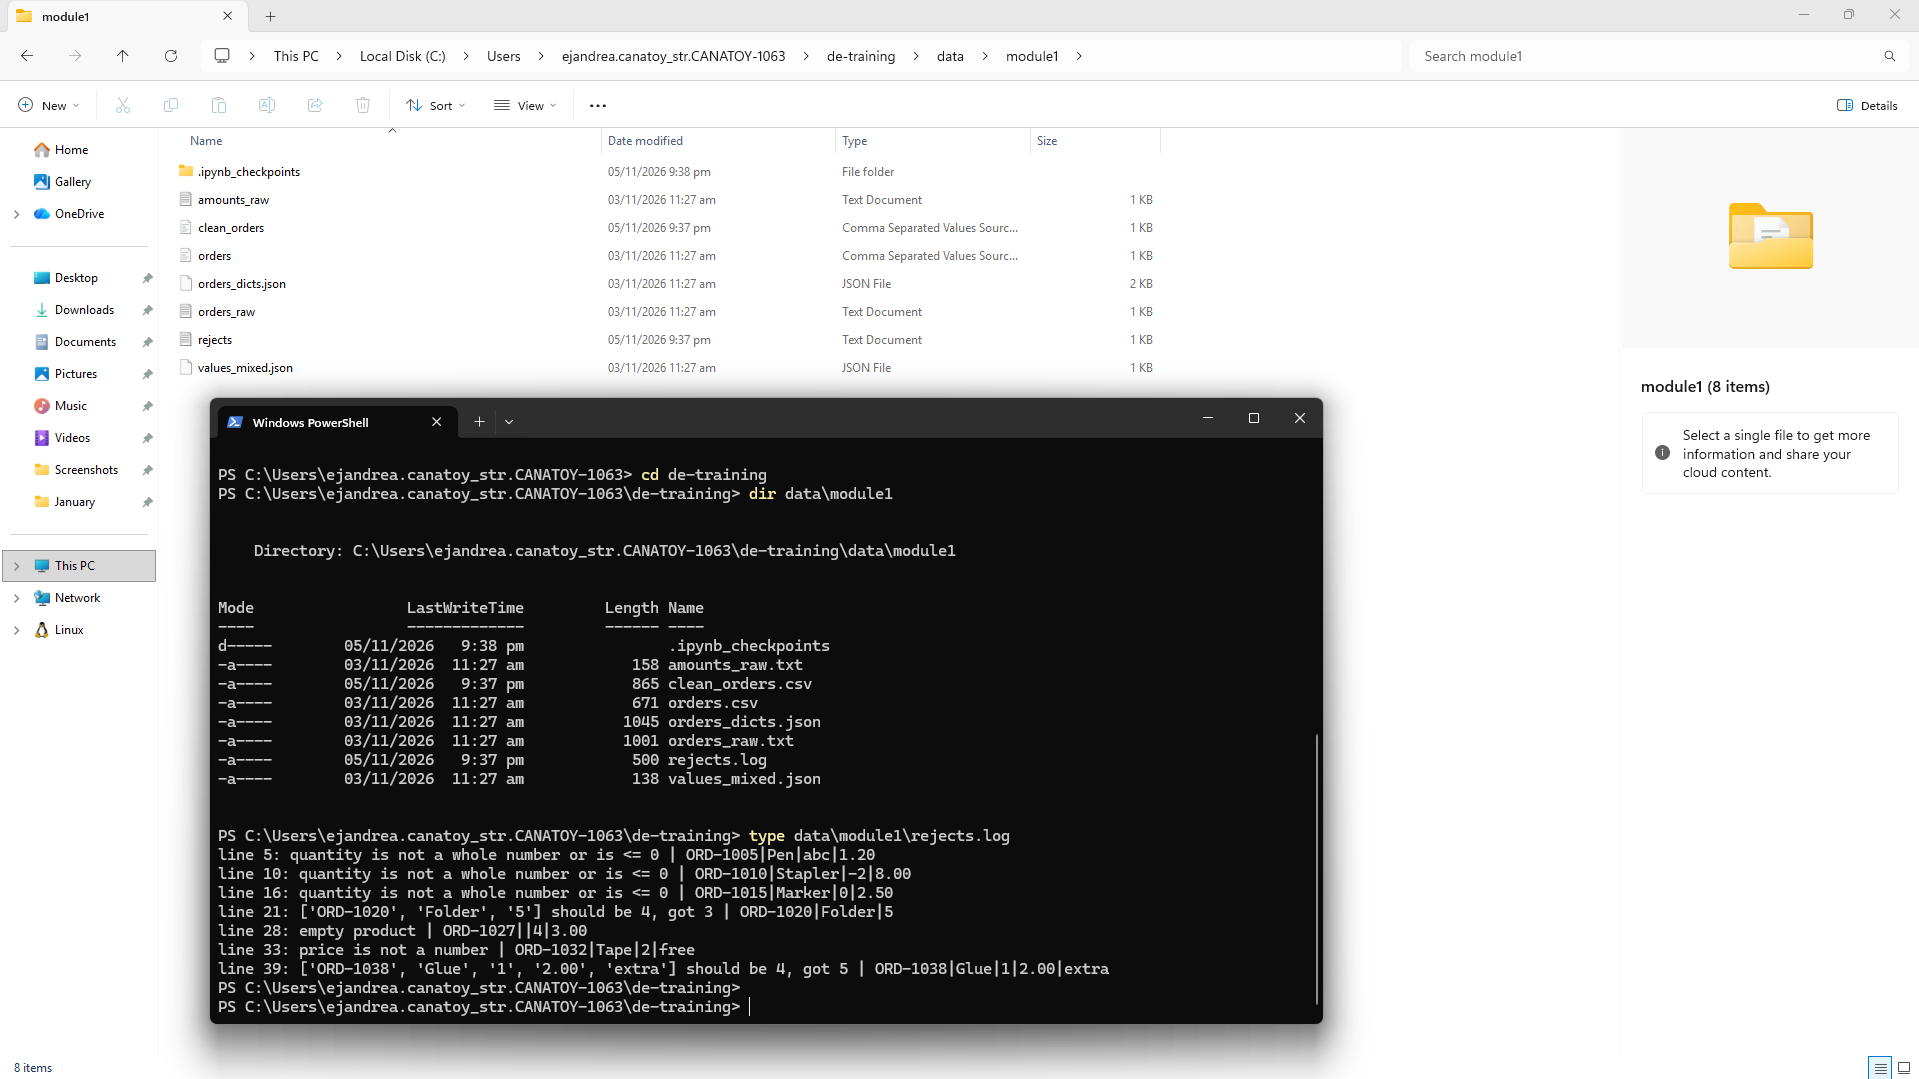

#### why with open() instead of plain open()

Both with open() and open() are ways of opening a file but with open() guarantees the closing of the file as it hits a stop (block finishes or error occurs), for a regular open(), it must be manually closed. Since the code is manually closed, if the error happened before the manual closing of the file, the file stays open in memory and can cause data corruption.

## 1.5 Functions

### B-1.5.1 Refactor the Lab 1.4 script 

Refactor the Lab 1.4 script into at least four documented functions (`read_lines`, `parse_record`, `validate_record`, `write_outputs`) (Lab 1.5 step 1).

In [18]:
import csv

FIELD_NAMES = ("order_id", "product", "quantity", "unit_price")

# helper function earlier
def is_number(value):
    """Return True if value can be converted to a float, False otherwise."""
    try:
        safe_to_float(value)
    except (ValueError, TypeError):
        return False
    return True


def read_lines(input_path):
    """Return (line_number, line) pairs for every non-blank line in the file."""
    lines = []
    with open(input_path) as infile:
        for line_number, line in enumerate(infile, start=1):
            if line.strip():
                lines.append((line_number, line))
    return lines


def parse_record(line):
    """Split a raw line on '|' and strip spaces from each field."""
    return [field.strip() for field in line.split("|")]


def validate_record(fields):
    """Return the reason a record is invalid, or None if it's valid."""
    if len(fields) != 4:
        return f"expected 4 fields, got {len(fields)}"
    if fields[0] == "":
        return "empty order_id"
    if fields[1] == "":
        return "empty product"
    if not fields[2].isdigit() or int(fields[2]) <= 0:
        return "quantity must be a whole number above 0"
    if not is_number(fields[3]):
        return "price is not a number"
    return None


def write_outputs(valid_rows, rejects, clean_path, rejects_path, header=FIELD_NAMES):
    """Write valid rows to a CSV (with a header) and reject messages to a log file."""
    with open(clean_path, "w", newline="") as clean_file, \
         open(rejects_path, "w") as rejects_file:
        writer = csv.writer(clean_file)
        writer.writerow(header)
        writer.writerows(valid_rows)
        for reject in rejects:
            rejects_file.write(reject + "\n")


# Main script

valid_rows, rejects = [], []

try:
    for line_number, line in read_lines(input_path):
        fields = parse_record(line)
        reason = validate_record(fields)
        if reason:
            rejects.append(f"line {line_number}: {reason} | {line.rstrip()}")
        else:
            valid_rows.append(fields)
except FileNotFoundError:
    print(f"{input_path} does not exist.")
else:
    write_outputs(valid_rows, rejects, clean_path=clean_path, rejects_path=rejects_path)
    print(f"Valid: {len(valid_rows)}, Rejected: {len(rejects)}")
    print(f"\nRejects:\n{rejects_path.read_text()}")

Valid: 33, Rejected: 7

Rejects:
line 5: quantity must be a whole number above 0 | ORD-1005|Pen|abc|1.20
line 10: quantity must be a whole number above 0 | ORD-1010|Stapler|-2|8.00
line 16: quantity must be a whole number above 0 | ORD-1015|Marker|0|2.50
line 21: expected 4 fields, got 3 | ORD-1020|Folder|5
line 28: empty product | ORD-1027||4|3.00
line 33: price is not a number | ORD-1032|Tape|2|free
line 39: expected 4 fields, got 5 | ORD-1038|Glue|1|2.00|extra



#### Why split the pipeline into functions

Splitting the pipeline into functions makes it more readable, since each job gets its own separate block of code. Each function is also easier to reuse and can be tested on its own.

### B-1.5.2 Default and Keyword arguments

Show one function with a default argument and one called with keyword arguments (Lab 1.5 step 2).

In [19]:
def register_user(first_name, last_name, role="User"):
    if role == "Admin":
        return f'Hello, Admin {first_name}!'
    else:
        return f'Hello, {first_name} {last_name}!'

print(register_user('John', 'Cruz')) # uses the default argument since I didn't pass a third argument
print(register_user('John', 'Cruz', role='Admin')) # keyword argument since I've named the role parameter

Hello, John Cruz!
Hello, Admin John!


### B-1.5.3 Mutable default argument trap

Demonstrate the mutable-default-argument trap and the `None` fix (Lab 1.5 step 3).

In [20]:
# Mutable default argument trap

def add_item(item, basket=[]):      
    basket.append(item)
    return basket

add_item("pen")                     
print(add_item("ink"))  # ['pen', 'ink']  <- the same list again

# This happens because the default list is created once, when the function is defined, 
# not on each call

['pen', 'ink']


In [21]:
# The fix is to use None and create a new list inside the function whenever an argument isn't passed

def add_item(item, basket=None):
    if basket is None:
        basket = []
    basket.append(item)
    return basket

add_item("pen")                     
print(add_item("ink"))  # ['ink']  <- only shows the ink

['ink']


#### Mutable Default Argument

A mutable default like basket=[] is shared across calls, so items from an earlier call show up in later ones. This happens because the default list is created once when the function is defined, not on each call. The fix is to use None as the default and create a new list inside the function whenever no argument is passed, so each call gets its own list.

## 1.6 Lambda

### B-1.6.1: Sort with lambda

Sort a list of order dictionaries by amount descending with `sorted(..., key=lambda ...)` (Lab 1.6 step 1).

In [22]:
orders_dicts = json.loads((DATA_DIR / "orders_dicts.json").read_text())

sorted(orders_dicts, key=lambda order: order['amount'], reverse=True) # reverse true sorts in desc order

[{'order_id': 'ORD-3001', 'product': 'Stapler', 'amount': 239.78},
 {'order_id': 'ORD-3004', 'product': 'Stapler', 'amount': 196.94},
 {'order_id': 'ORD-3003', 'product': 'Glue', 'amount': 168.8},
 {'order_id': 'ORD-3011', 'product': 'Tape', 'amount': 163.34},
 {'order_id': 'ORD-3007', 'product': 'Stapler', 'amount': 132.41},
 {'order_id': 'ORD-3006', 'product': 'Glue', 'amount': 100.65},
 {'order_id': 'ORD-3009', 'product': 'Pen', 'amount': 100.39},
 {'order_id': 'ORD-3008', 'product': 'Marker', 'amount': 97.12},
 {'order_id': 'ORD-3005', 'product': 'Ruler', 'amount': 79.97},
 {'order_id': 'ORD-3002', 'product': 'Eraser', 'amount': 76.22},
 {'order_id': 'ORD-3010', 'product': 'Pen', 'amount': 17.59},
 {'order_id': 'ORD-3012', 'product': 'Notebook', 'amount': 11.27}]

### B-1.6.2: Lambda and a list comprehension

Apply a 12% tax with `map` and a lambda, then redo it as a list comprehension (Lab 1.6 step 2).

In [23]:
amounts = [order["amount"] for order in orders_dicts]

# wrapped in a list because map is a lazy loader, used 1.12 to calculate total price including tax
taxed_map = list(map((lambda amount: round(amount * 1.12, 2)), amounts))
print(taxed_map)

[268.55, 85.37, 189.06, 220.57, 89.57, 112.73, 148.3, 108.77, 112.44, 19.7, 182.94, 12.62]


In [24]:
# Rewriting the same logic above as a list comprehension

taxed_comp = [round(amount * 1.12, 2) for amount in amounts] # easier to read
print(taxed_comp)

print(taxed_map == taxed_comp)

[268.55, 85.37, 189.06, 220.57, 89.57, 112.73, 148.3, 108.77, 112.44, 19.7, 182.94, 12.62]
True


#### When not to use a lambda

A lambda is fine for short expressions that are used once and don’t need to be reused or tested on their own. However, when the logic needs more than one step or a try block, or needs a descriptive name to be understood by others, a named function is the better choice. For example, my validate_record function from Lab 1.5 couldn’t be a lambda, since it has several checks and returns different reasons.

## 1.7 Object-oriented programming

### B-1.7.1 + B-1.7.2: OrderRecord Class and count attribute

Write the `OrderRecord` class with `__init__`, `total()`, a readable `__repr__`, and a `ValueError` for non-positive quantity (Lab 1.7 step 1).

Add a class attribute counting records created; show how it differs from an instance attribute and what assigning through an instance does (Lab 1.7 step 2).

In [25]:
class OrderRecord:
    count = 0 # class attribute, shared by all records
    
    def __init__(self, order_id, product, quantity, unit_price):
        self.order_id = order_id
        self.product = product
        self.quantity = quantity
        self.unit_price = unit_price

        try:
            self.quantity = int(quantity)
        except ValueError as err:
            raise ValueError(f"quantity must be a whole number, got {quantity!r}") from err
        
        if self.quantity <= 0:
            raise ValueError(f"quantity must be above 0, got {self.quantity}")
        
        self.unit_price = safe_to_float(unit_price)
        OrderRecord.count += 1
    
    def total(self):
        return round(self.quantity * self.unit_price, 2)

    def __repr__(self):
        return f"OrderRecord({self.order_id!r}, {self.product!r}, {self.quantity}, {self.unit_price})"

In [43]:
try:
    OrderRecord("ORD-1002", "Eraser", "0", "1.20")
except ValueError as err:
    print(f"ValueError: {err}")

ValueError: quantity must be above 0, got 0


In [27]:
OrderRecord.count = 0

record = OrderRecord("ORD-1001", "Pen", "11", "1.20")
second_record = OrderRecord("ORD-1002", "Eraser", "14", "1.03")
third_record = OrderRecord("ORD-1003", "Pencil", "22", "0.20")

print(f"Class Attribute: {OrderRecord.count}")
print(f"Instance Attribute: {record.count}")

record.count = 100

print("\nAfter re-assignment ---")
print(f"Class Attribute: {OrderRecord.count}")
print(f"Instance Attribute: {record.count}")

Class Attribute: 3
Instance Attribute: 3

After re-assignment ---
Class Attribute: 3
Instance Attribute: 100


#### Instance Attribute vs Class Attribute

A class attribute is an attribute shared and seen by all instances. Assigning through an instance creates a new instance attribute and hides the class attribute for that one object, while all the other instances still see the class attribute's value.

### B-1.7.3: OrderReader Class

Write the `OrderReader` base class and the `TextOrderReader` and `CsvOrderReader` subclasses, using `super()` in at least one (Lab 1.7 step 3).

In [28]:
import csv

class OrderReader:
    def __init__(self, path):
        self.path = path

    def read(self):
        # forces the subclasses to have their own read(), raises an error if they don't
        raise NotImplementedError('subclasses must implement read()')


class TextOrderReader(OrderReader):
    def read(self):
        orders = []
        # reuses read_lines and parse_record from lab 1.5 so the logic isn't repeated
        for line_number, line in read_lines(self.path):
            orders.append((line_number, parse_record(line)))
        return orders


class CsvOrderReader(OrderReader):
    # reads orders from a csv file with a header row like orders.csv
    def __init__(self, path, delimiter=','):
        super().__init__(path)  # the base class already stores the path so we just reuse it
        self.delimiter = delimiter  # only the csv reader needs a delimiter

    def read(self):
        orders = []
        with open(self.path, newline='') as f:
            csv_rows = csv.reader(f, delimiter=self.delimiter)
            next(csv_rows)  # skips the header, the next rows start from line 2

            # starts at 2 because file assumes header is at line 1
            for line_number, row in enumerate(csv_rows, start=2):
                fields = [field.strip() for field in row]  # clean each field
                orders.append((line_number, fields))

        return orders

In [29]:
text_reader = TextOrderReader(DATA_DIR / 'orders_raw.txt')
csv_reader = CsvOrderReader(DATA_DIR / 'orders.csv')

# both readers should give the same shape (line_number, fields) even if the files are different
for reader in (text_reader, csv_reader):
    rows = reader.read()
    print(f'{reader.path.name}: {len(rows)} rows')
    print(f'First 2: {rows[:2]}\n')

# the base class has a read() but it only raises an error
try:
    OrderReader(DATA_DIR / 'orders.csv').read()
except NotImplementedError as err:
    print(f'OrderReader: NotImplementedError: {err}')

orders_raw.txt: 40 rows
First 2: [(1, ['ORD-1001', 'Pen', '11', '1.20']), (2, ['ORD-1002', 'Eraser', '17', '0.80'])]

orders.csv: 25 rows
First 2: [(2, ['ORD-2001', 'Eraser', '13', '0.80']), (3, ['ORD-2002', 'Notebook', '10', '4.50'])]

OrderReader: NotImplementedError: subclasses must implement read()


### B-1.7.4: load_orders function

Write `load_orders(reader)` that works unchanged with either reader (Lab 1.7 step 4).

In [30]:
def load_orders(reader):
    records = []
    rejects = []

    # works with any reader since they all return (line_number, fields)
    for line_number, fields in reader.read():
        reason = validate_record(fields)  # reuses the checks from lab 1.5

        if reason:
            rejects.append(f'line {line_number}: {reason}')
        else:
            records.append(OrderRecord(*fields))

    return records, rejects

In [31]:
for reader in (text_reader, csv_reader):
    records, rejects = load_orders(reader)
    print(f'{reader.path.name}: {len(records)} records, {len(rejects)} rejects')

print('\nFirst 5 records:')
for record in records[:5]:
    print(record)

orders_raw.txt: 33 records, 7 rejects
orders.csv: 22 records, 3 rejects

First 5 records:
OrderRecord('ORD-2001', 'Eraser', 13, 0.8)
OrderRecord('ORD-2002', 'Notebook', 10, 4.5)
OrderRecord('ORD-2003', 'Marker', 13, 2.5)
OrderRecord('ORD-2004', 'Stapler', 14, 8.0)
OrderRecord('ORD-2005', 'Notebook', 12, 4.5)


### B-1.7.5: OrderPipeline Class

Write the `OrderPipeline(reader, writer)` class with a `run()` method returning valid and rejected counts (Lab 1.7 step 5).

In [32]:
class CsvOrderWriter:
    def __init__(self, clean_path, rejects_path):
        self.clean_path = clean_path
        self.rejects_path = rejects_path

    def write(self, records, rejects):
        # turn OrderRecord objects back into rows for write_outputs
        rows = [[r.order_id, r.product, r.quantity, r.unit_price] for r in records]
        write_outputs(rows, rejects, self.clean_path, self.rejects_path)

class OrderPipeline:
    def __init__(self, reader, writer):
        self.reader = reader
        self.writer = writer

    def run(self):
        records, rejects = load_orders(self.reader)
        self.writer.write(records, rejects)
        
        return len(records), len(rejects)

In [33]:
for reader in (text_reader, csv_reader):
    writer = CsvOrderWriter(DATA_DIR / f'clean_{reader.path.stem}_1-7.csv',
                            DATA_DIR / f'rejects_{reader.path.stem}_1-7.log')
    valid, rejected = OrderPipeline(reader, writer).run()
    print(f'{reader.path.name}: {valid} valid, {rejected} rejected')

orders_raw.txt: 33 valid, 7 rejected
orders.csv: 22 valid, 3 rejected


**OrderPipeline** uses composition because a pipeline has a reader and a writer, it isn’t a type of reader. Because it only calls read() and write(), I could pass TextOrderReader or CsvOrderReader without changing the class, and it gave 33/7 and 22/3. If it inherited from a reader instead, I’d need a separate pipeline class for each reader, which means duplicated code.

**When a function is enough and a class is not needed:**

A function is enough if there is no need for retaining data between calls. A class with only a single action method is unnecessary and should be a function instead.

## 1.8 Modular Programming

### B-1.8.1 + ### B-1.8.2: 

Moved the Lab 1.4–1.7 code into the `orders_pipeline/` package with seven files. Each module starts with a one-sentence docstring that says its single job. The cell below prints the first line of every module.

In [44]:
!head -n 1 /workspace/work/orders_pipeline/*.py

==> /workspace/work/orders_pipeline/__init__.py <==
"""Order cleaning pipeline: reads raw orders, validates them, and writes clean and rejected rows."""

==> /workspace/work/orders_pipeline/__main__.py <==
"""Entry point -> runs the pipeline on orders_raw.txt when called with python -m orders_pipeline"""

==> /workspace/work/orders_pipeline/models.py <==
"""Defines OrderRecord, the object that holds one valid order."""

==> /workspace/work/orders_pipeline/pipeline.py <==
"""Connects a reader and a writer: loads orders, splits valid from rejected, and writes both."""

==> /workspace/work/orders_pipeline/readers.py <==
"""Reads orders from a text or CSV file and returns them as (line_number, fields) pairs"""

==> /workspace/work/orders_pipeline/validators.py <==
""" Checks whether values and records are valid, tells the reason why they aren't"""

==> /workspace/work/orders_pipeline/writers.py <==
"""Writes clean orders to a CSV file and rejected orders to a log file."""


### B-1.8.3

Made a circular import on purpose by moving `safe_to_float` into `pipeline.py` and importing it in `models.py`.

Error: `ImportError: cannot import name 'safe_to_float' from partially initialized module 'orders_pipeline.pipeline' (most likely due to a circular import)`

Cause: `pipeline.py` imports `OrderRecord` from `models.py`, and `models.py` imported `safe_to_float` from `pipeline.py`, so each was waiting for the other to finish loading.

Fix: moved `safe_to_float` back to `validators.py`, which imports nothing from the package, and imported it from there.

![circular import break it yourself fix.png](<attachment:circular import break it yourself fix.png>)
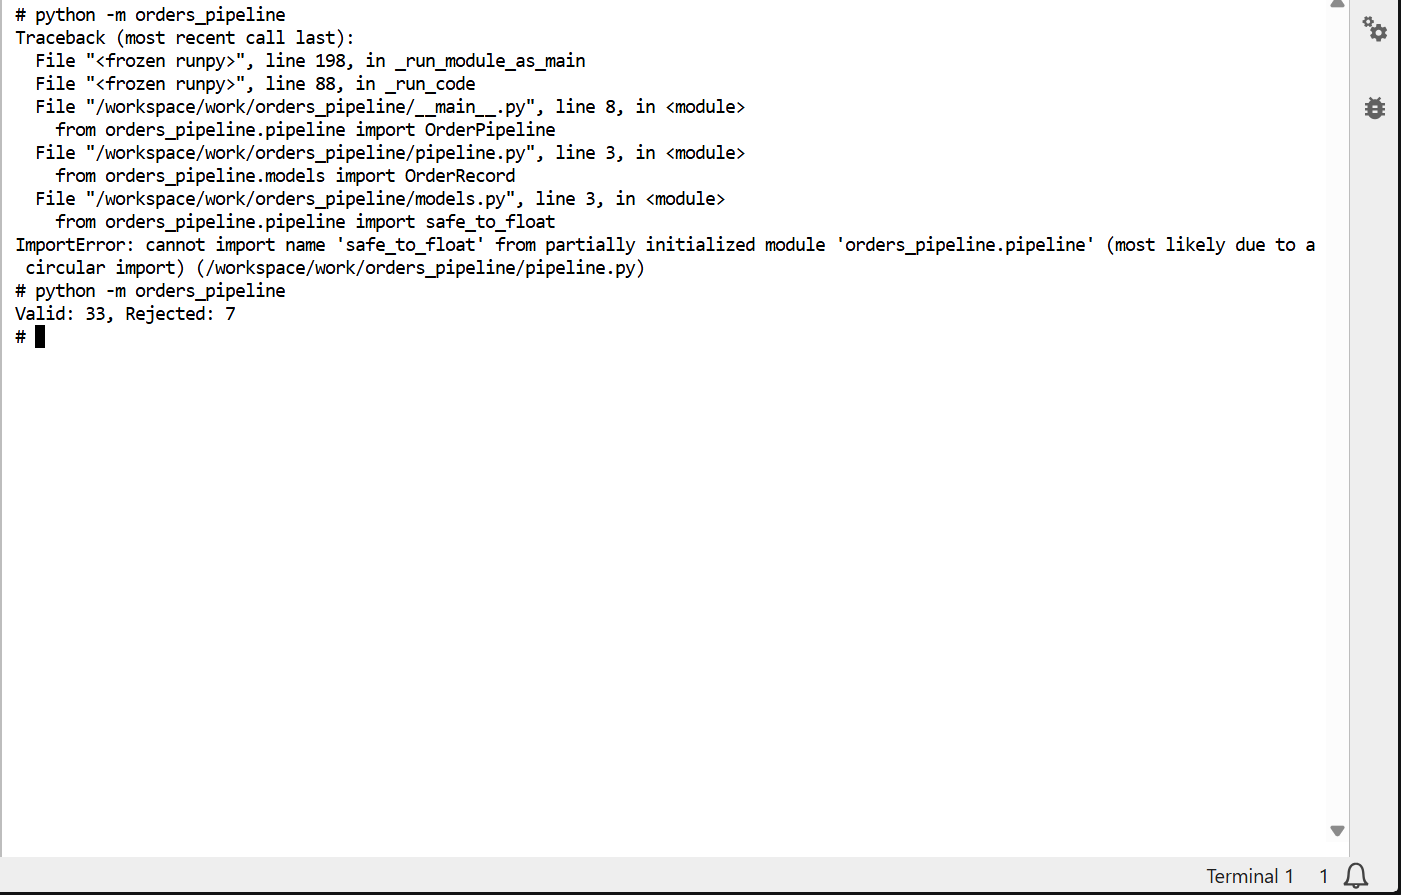

### B-1.8.6

The notebook only imports from the package, so no code is copied here. `%autoreload 2` reloads the package when I edit a `.py` file. Below: the folder tree, one module's contents, and the pipeline running with both readers.

In [35]:
%cd /workspace/work
%load_ext autoreload
%autoreload 2

from orders_pipeline import TextOrderReader, CsvOrderReader, CsvOrderWriter, OrderPipeline

/workspace/work


In [36]:
!find orders_pipeline -name "*.py" | sort
!cat orders_pipeline/pipeline.py

orders_pipeline/__init__.py
orders_pipeline/__main__.py
orders_pipeline/models.py
orders_pipeline/pipeline.py
orders_pipeline/readers.py
orders_pipeline/validators.py
orders_pipeline/writers.py
"""Connects a reader and a writer: loads orders, splits valid from rejected, and writes both."""

from orders_pipeline.models import OrderRecord
from orders_pipeline.validators import validate_record

def load_orders(reader):
    """Read with any reader and return (records, rejects)."""
    records = []
    rejects = []
    for line_number, fields in reader.read():
        reason = validate_record(fields)
        if reason:
            rejects.append(f"line {line_number}: {reason}")
        else:
            records.append(OrderRecord(*fields))
    return records, rejects


class OrderPipeline:
    def __init__(self, reader, writer):
        self.reader = reader
        self.writer = writer

    def run(self):
        records, rejects = load_orders(self.reader)
        self.writer.write(records,

cat: orders_pipeline/pipeline.py: No such file or directory


## Integration

The package running end to end from the notebook (with both readers) and from the container terminal (`python -m orders_pipeline`), then the output files compared.

In [37]:
reader = TextOrderReader(DATA_DIR / "orders_raw.txt")
writer = CsvOrderWriter(DATA_DIR / "clean_orders_notebook.csv", DATA_DIR / "rejects_notebook.log")
print("orders_raw.txt:", OrderPipeline(reader, writer).run())

reader = CsvOrderReader(DATA_DIR / "orders.csv")
writer = CsvOrderWriter(DATA_DIR / "clean_orders_csv.csv", DATA_DIR / "rejects_orders_csv.log")
print("orders.csv:", OrderPipeline(reader, writer).run())

orders_raw.txt: (33, 7)
orders.csv: (22, 3)



### B-1.8.4 + ### B-1.8.5

`check_pipeline.py` has three asserts: valid + rejected equals the non-blank input lines, no negative totals in the clean file, and every reject has a reason. Below, the package runs the same way as from the container terminal (`python -m orders_pipeline`), then the checks run on its output.

In [38]:
!python -m orders_pipeline
!python check_pipeline.py

Valid: 33, Rejected: 7
All 3 checks passed: 33 valid + 7 rejected = 40 lines


### V-1.8.3

Checks that the terminal run and the notebook run give identical output files, and that the package's clean file matches Lab 1.4's `clean_orders.csv`. `shallow=False` compares the actual contents.

In [39]:
import filecmp

# terminal run vs notebook run
print("clean files same:", filecmp.cmp(DATA_DIR / "clean_orders_terminal.csv", DATA_DIR / "clean_orders_notebook.csv", shallow=False))
print("rejects files same:", filecmp.cmp(DATA_DIR / "rejects_terminal.log", DATA_DIR / "rejects_notebook.log", shallow=False))

# package vs Lab 1.4
print("same as Lab 1.4:", filecmp.cmp(DATA_DIR / "clean_orders_terminal.csv", DATA_DIR / "clean_orders.csv", shallow=False))

clean files same: True
rejects files same: True
same as Lab 1.4: True


## Evidence

The folder tree is in B-1.8.6 and `check_pipeline.py` passing is in B-1.8.4 + B-1.8.5. Below: the `requirements.txt` the image was built from, the first rows of `clean_orders.csv`, and `rejects.log`.

In [45]:
!cat /tmp/requirements.txt
!echo
!head -n 6 /workspace/data/module1/clean_orders.csv
!echo
!cat /workspace/data/module1/rejects.log

jupyterlab==4.4.0
tabulate==0.9.0
order_id,product,quantity,unit_price
ORD-1001,Pen,11,1.20
ORD-1002,Eraser,17,0.80
ORD-1003,Pen,8,1.20
ORD-1004,Ruler,20,1.50
ORD-1006,Eraser,14,0.80

line 5: quantity must be a whole number above 0 | ORD-1005|Pen|abc|1.20
line 10: quantity must be a whole number above 0 | ORD-1010|Stapler|-2|8.00
line 16: quantity must be a whole number above 0 | ORD-1015|Marker|0|2.50
line 21: expected 4 fields, got 3 | ORD-1020|Folder|5
line 28: empty product | ORD-1027||4|3.00
line 33: price is not a number | ORD-1032|Tape|2|free
line 39: expected 4 fields, got 5 | ORD-1038|Glue|1|2.00|extra


## Diagrams

### 1-A Exception flow (Lab 1.3)

```mermaid
flowchart TD
    A["value from values_mixed.json"] --> B["try: safe_to_float(value)"]
    B -->|"works"| C["else: append result to valid_values"]
    B -->|"bad string, e.g. 'abc' or ''"| D["except ValueError: count it, print the message"]
    B -->|"wrong type, e.g. None"| E["except TypeError: count it, print the message"]
    C --> F["finally: print Processed + the value"]
    D --> F
    E --> F
    F --> G{"more values?"}
    G -->|"yes"| A
    G -->|"no"| H["print counts: 8 valid, 5 ValueError, 2 TypeError"]
```

### 1-B Text-file mini pipeline (Lab 1.4)

```mermaid
flowchart TD
    A[("orders_raw.txt")] --> B["with open(...) — read line by line"]
    B --> C{"blank line?"}
    C -->|"yes"| B
    C -->|"no"| D["split on | and strip each field"]
    D --> E{"validate: 4 fields, order_id, product, quantity > 0, price is a number"}
    E -->|"valid"| F[("clean_orders.csv")]
    E -->|"invalid"| G[("rejects.log: line number + reason")]
    A -. "file missing" .-> H["except FileNotFoundError: print a message"]
```

### 1-C Class design (Lab 1.7)

```mermaid
classDiagram
    class OrderRecord {
        count = 0
        order_id
        product
        quantity
        unit_price
        total()
        __repr__()
    }
    class OrderReader {
        path
        read()
    }
    class TextOrderReader {
        read()
    }
    class CsvOrderReader {
        delimiter
        read()
    }
    class CsvOrderWriter {
        clean_path
        rejects_path
        write(records, rejects)
    }
    class OrderPipeline {
        reader
        writer
        run()
    }
    OrderReader <|-- TextOrderReader : inherits
    OrderReader <|-- CsvOrderReader : inherits, uses super()
    OrderPipeline o-- OrderReader : has a
    OrderPipeline o-- CsvOrderWriter : has a
    OrderPipeline ..> OrderRecord : creates via load_orders
```

### 1-D Package structure (Lab 1.8)

Arrows point to the module being imported. `validators.py` imports nothing from the package, which is why shared code lives there.

```mermaid
flowchart LR
    main["__main__.py<br/>entry point"] --> pipeline["pipeline.py<br/>load_orders, OrderPipeline"]
    main --> readers["readers.py<br/>read_lines, parse_record, readers"]
    main --> writers["writers.py<br/>write_outputs, CsvOrderWriter"]
    pipeline --> models["models.py<br/>OrderRecord"]
    pipeline --> validators["validators.py<br/>safe_to_float, is_number, validate_record"]
    models --> validators
    init["__init__.py<br/>re-exports"] --> models
    init --> readers
    init --> writers
    init --> pipeline
    notebook["notebook"] --> init
    check["check_pipeline.py"] --> readers
```

## What broke and how I fixed it

| Lab | Error | Cause | Fix |
|---|---|---|---|
| Setup | `ModuleNotFoundError: No module named 'config'` | The notebook was at JupyterLab's top level (`/workspace`), so Python couldn't see `work/config.py` | Moved the notebook into `work/` and restarted the kernel |
| 1.1 | `TypeError: unsupported operand type(s) for +: 'int' and 'str'` | `sum()` starts at 0, and the quantities were still strings like `'13'` | Wrapped the quantity in `int(...)`, which is safe because `isdigit()` already filtered out bad values |
| 1.2 | `ModuleNotFoundError: No module named 'tabulate'` | `tabulate` is a third-party package and wasn't in the image yet | Added `tabulate==0.9.0` to `requirements.txt`, rebuilt the image and restarted the container |
| 1.8 | `ImportError: cannot import name 'safe_to_float' from partially initialized module 'orders_pipeline.pipeline' (most likely due to a circular import)` | Made on purpose: `pipeline.py` imports `OrderRecord` from `models.py`, and `models.py` imported `safe_to_float` from `pipeline.py`, so each was waiting for the other to finish loading | Moved `safe_to_float` back to `validators.py`, which imports nothing from the package, and imported it from there |
| 1.8 | `ImportError: cannot import name 'TextOrderReader' from 'orders_pipeline' (unknown location)` | The file was named `__init.__.py` (extra dot), so Python saw a folder with no `__init__.py` and the re-exports never ran. The terminal run still worked because `python -m` doesn't need it | Renamed it to `__init__.py` and restarted the kernel |

## Reflection

The hardest part for me was packages (Lab 1.8), since I was scouring through multiple files. Small mistakes like a misspelled folder name or file name broke the imports, and the errors didn’t point straight at the cause. Next time I’d check file names with `ls` first before debugging the code. What clicked for me, though, was where shared code should live so imports don’t go in a circle, and how the notebook just imports the package instead of copying code.